# Additive vs MULTI-evolve comparison — HuABC2 (anti-CD122 antibody)

Compare additive (RidgeCV) predictions against MULTI-evolve NN predictions
across the combinatorial mutation space for HuABC2, a multi-chain antibody
with VH and VL domains.

Two measurements: **expression** (fold improvement) and **binding** (fold improvement).

Mutations use MULTI-evolve multi-chain format: `VH_muts:VL_muts`
(e.g. `Q13P/S51I:L21I/S28P`).

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from itertools import combinations
from scipy.stats import pearsonr
import os
import re

os.makedirs('../figures', exist_ok=True)

In [2]:
full_df = pd.read_excel('../data/Table S16 HuABC2 variants.xlsx')
full_df = full_df[[x for x in full_df.columns.values if 'Unnamed' not in x]]

# Log2-transform both measurements
for col, tag in [('Fold Improvement (Expression)', 'logfc_expr'),
                 ('Fold Improvement (Binding)', 'logfc_bind')]:
    full_df[tag] = pd.to_numeric(full_df[col], errors='coerce').apply(np.log2)

full_df

,Mutations,Fold Improvement (Expression),Fold Improvement (Binding),Origin,Variant ID,Legend,logfc_expr,logfc_bind
0,WT:WT,1.000000,1.000000,NaN,NaN,WT = wild-type sequence,0.000000,0.000000
1,WT:C23W,0.001000,NaN,PLM zeroshot,NaN,Mutations are formatted as {original amino aci...,-9.965784,NaN
2,WT:P43T,0.130000,NaN,PLM zeroshot,NaN,For HuABC2 the colon separates the individual ...,-2.943416,NaN
3,WT:L46T,0.149000,NaN,PLM zeroshot,NaN,NaN,-2.746616,NaN
4,WT:G100V,0.072000,NaN,PLM zeroshot,NaN,NaN,-3.795859,NaN
...,...,...,...,...,...,...,...,...
327,L11Q/Q13P/S51I:L21I/S24R/S28P/I105P,2.802804,1.118451,MULTI-evolve variant,NaN,NaN,1.486871,0.161503
328,L11Q/Q13P/S51I/T116L:L21I/S28P/I105P,3.463131,0.982066,MULTI-evolve variant,v10,NaN,1.792077,-0.026108
329,L11Q/Q13P/S51I:L21I/S28P/S30P/I105P,3.553753,0.925734,MULTI-evolve variant,NaN,NaN,1.829343,-0.111331
330,Q13P/S51I/T116L:L21I/S24R/S28P/I105P,3.793329,0.918581,MULTI-evolve variant,v9,NaN,1.923464,-0.122521


In [3]:
def parse_chain_muts(mutation_str):
    """Parse 'VH_muts:VL_muts' into (vh_list, vl_list)."""
    parts = mutation_str.split(':')
    vh = [m for m in parts[0].split('/') if m != 'WT']
    vl = [m for m in parts[1].split('/') if m != 'WT']
    return vh, vl


def flat_muts(mutation_str):
    """Return flat list of all mutations with chain prefixes."""
    vh, vl = parse_chain_muts(mutation_str)
    return [f'VH_{m}' for m in vh] + [f'VL_{m}' for m in vl]


def count_muts(mutation_str):
    vh, vl = parse_chain_muts(mutation_str)
    return len(vh) + len(vl)

In [4]:
# Process singles — build effect dictionaries for both measurements
singles = full_df[full_df['Origin'] == 'PLM zeroshot'].copy()

effect_dictionary = {}
for tag in ['logfc_expr', 'logfc_bind']:
    # Map chain-prefixed mutation name -> log2 fold change
    d = {}
    for _, row in singles.iterrows():
        fm = flat_muts(row['Mutations'])
        assert len(fm) == 1, f'Expected single mutation: {row["Mutations"]}'
        val = row[tag]
        if pd.notna(val):
            d[fm[0]] = val
    effect_dictionary[f'single_effect_{tag}'] = d
    print(f'{tag}: {len(d)} singles with data')

logfc_expr: 132 singles with data
logfc_bind: 93 singles with data


In [5]:
# Process doubles — compute additive predictions and epistatic residuals
doubles = full_df[full_df['Origin'] == 'Double Mutant'].copy()
doubles['flat_muts'] = doubles['Mutations'].apply(flat_muts)
doubles['n_muts'] = doubles['flat_muts'].apply(len)

for tag in ['logfc_expr', 'logfc_bind']:
    se = effect_dictionary[f'single_effect_{tag}']
    doubles[f'single_prediction_{tag}'] = doubles['flat_muts'].apply(
        lambda ms: sum(se.get(m, np.nan) for m in ms))
    doubles[f'epistatic_effect_{tag}'] = doubles[tag] - doubles[f'single_prediction_{tag}']
    # Store in effect dictionary for downstream use
    for _, row in doubles.iterrows():
        key = '/'.join(sorted(row['flat_muts']))
        effect_dictionary.setdefault(f'epistatic_effect_{tag}', {})[key] = row[f'epistatic_effect_{tag}']

print(f'Doubles: {len(doubles)}')
doubles[['Mutations', 'logfc_expr', 'single_prediction_logfc_expr',
         'epistatic_effect_logfc_expr', 'logfc_bind',
         'single_prediction_logfc_bind', 'epistatic_effect_logfc_bind']].head(10)

Doubles: 169


,Mutations,logfc_expr,single_prediction_logfc_expr,epistatic_effect_logfc_expr,logfc_bind,single_prediction_logfc_bind,epistatic_effect_logfc_bind
133,L11Q:Y93W,-0.448115,0.529795,-0.977910,1.064883,0.840485,0.224398
134,Q13P:L21I,0.790772,1.074801,-0.284029,0.273112,0.821317,-0.548205
135,Q13P:R18T,0.282143,0.892614,-0.610471,0.336357,0.834512,-0.498155
136,Q13P:I105P,0.347099,0.519586,-0.172488,0.461731,0.932880,-0.471149
137,T116L:I105P,0.273814,0.687011,-0.413196,0.502362,0.470513,0.031849
138,S51I:I105P,-0.192645,0.340906,-0.533551,0.803227,0.865207,-0.061980
139,T116L:I105L,0.531069,1.069480,-0.538411,0.311027,0.187920,0.123107
140,S51I:S28P,0.285698,0.929952,-0.644254,0.745022,0.820557,-0.075535
141,T116L:L21I,0.941106,1.242226,-0.301119,0.258504,0.358950,-0.100446
142,S51I:T20V,-0.217591,0.775137,-0.992729,0.712816,0.198744,0.514072


In [6]:
# MULTI-evolve variants from the paper
me_variants = full_df[full_df['Origin'] == 'MULTI-evolve variant'].copy()
me_variants['flat_muts'] = me_variants['Mutations'].apply(flat_muts)
me_variants['n_muts'] = me_variants['flat_muts'].apply(len)
me_variants['muts_s'] = me_variants['flat_muts'].apply(lambda x: str(sorted(x)))
targets = me_variants['muts_s']
print(f'MULTI-evolve variants (targets): {len(targets)}')
print(f'Mutation counts: {me_variants["n_muts"].value_counts().sort_index().to_dict()}')

MULTI-evolve variants (targets): 30
Mutation counts: {3: 6, 4: 6, 5: 6, 6: 6, 7: 6}


## Enumerate combinatorial pool

The mutation pool has 19 mutations: 4 VH (positions 11, 13, 51, 116) and
15 VL (13 unique positions — 105 and 93 each have two alternatives).

We enumerate combinations of 3–7 mutations, filtering out those with
multiple substitutions at the same position on the same chain.

In [7]:
# Build mutation pool with chain labels and positions
# combo_muts.csv uses chain notation: 'L11Q:WT' (VH) or 'WT:F82G' (VL)
combo_muts_raw = pd.read_csv(
    '../output/huabc2/combo_muts.csv', header=None)[0].tolist()

combo_pool = []
for entry in combo_muts_raw:
    parts = entry.split(':')
    # Chain 1 (VH) mutations
    for m in parts[0].split('/'):
        if m != 'WT':
            pos = int(re.search(r'(\d+)', m).group(1))
            combo_pool.append(('VH', m, pos))
    # Chain 2 (VL) mutations
    for m in parts[1].split('/'):
        if m != 'WT':
            pos = int(re.search(r'(\d+)', m).group(1))
            combo_pool.append(('VL', m, pos))

print(f'Combo pool: {len(combo_pool)} mutations '
      f'({sum(1 for c,_,_ in combo_pool if c=="VH")} VH, '
      f'{sum(1 for c,_,_ in combo_pool if c=="VL")} VL)')
for chain, mut, pos in combo_pool:
    print(f'  {chain}_{mut:8s} pos={pos}')

Combo pool: 19 mutations (4 VH, 15 VL)
  VH_L11Q     pos=11
  VH_Q13P     pos=13
  VH_S51I     pos=51
  VH_T116L    pos=116
  VL_F82G     pos=82
  VL_I105L    pos=105
  VL_I105P    pos=105
  VL_L21I     pos=21
  VL_L53R     pos=53
  VL_N52V     pos=52
  VL_R18T     pos=18
  VL_S24R     pos=24
  VL_S28P     pos=28
  VL_S30P     pos=30
  VL_T20V     pos=20
  VL_V84T     pos=84
  VL_Y70F     pos=70
  VL_Y93P     pos=93
  VL_Y93W     pos=93


In [8]:
# Enumerate combinations of 3-7 mutations, filtering site conflicts per chain
all_muts_rows = []
for n in range(3, 8):
    for combo in combinations(combo_pool, n):
        # Check for per-chain position conflicts
        seen = set()
        conflict = False
        for chain, mut, pos in combo:
            key = (chain, pos)
            if key in seen:
                conflict = True
                break
            seen.add(key)
        if conflict:
            continue
        
        flat = tuple(f'{chain}_{mut}' for chain, mut, pos in combo)
        # Build chain notation: VH_muts:VL_muts
        vh_part = '/'.join(mut for chain, mut, pos in combo if chain == 'VH') or 'WT'
        vl_part = '/'.join(mut for chain, mut, pos in combo if chain == 'VL') or 'WT'
        chain_notation = f'{vh_part}:{vl_part}'
        
        all_muts_rows.append({
            'muts': flat,
            'chain_notation': chain_notation,
            'n_muts': len(flat),
            'label': f'muts_{n}',
        })

all_muts = pd.DataFrame(all_muts_rows)
all_muts['muts_s'] = all_muts['muts'].apply(lambda x: str(sorted(x)))

print(f'Combinatorial pool: {len(all_muts):,} variants')
print(all_muts['label'].value_counts().sort_index())

Combinatorial pool: 75,767 variants
label
muts_3      935
muts_4     3605
muts_5    10283
muts_6    22477
muts_7    38467
Name: count, dtype: int64


In [9]:
# Build sub-doubles for each combination (used for one-hot encoding)
all_muts['double_muts'] = all_muts['muts'].apply(
    lambda x: ['/'.join(pair) for pair in combinations(x, 2)])

# Verify targets are present
found = all_muts['muts_s'].isin(targets).sum()
print(f'MULTI-evolve variants found in pool: {found} / {len(targets)}')
all_muts.head()

MULTI-evolve variants found in pool: 30 / 30


,muts,chain_notation,n_muts,label,muts_s,double_muts
0,"(VH_L11Q, VH_Q13P, VH_S51I)",L11Q/Q13P/S51I:WT,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VH_S51I']","[VH_L11Q/VH_Q13P, VH_L11Q/VH_S51I, VH_Q13P/VH_..."
1,"(VH_L11Q, VH_Q13P, VH_T116L)",L11Q/Q13P/T116L:WT,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VH_T116L']","[VH_L11Q/VH_Q13P, VH_L11Q/VH_T116L, VH_Q13P/VH..."
2,"(VH_L11Q, VH_Q13P, VL_F82G)",L11Q/Q13P:F82G,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VL_F82G']","[VH_L11Q/VH_Q13P, VH_L11Q/VL_F82G, VH_Q13P/VL_..."
3,"(VH_L11Q, VH_Q13P, VL_I105L)",L11Q/Q13P:I105L,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VL_I105L']","[VH_L11Q/VH_Q13P, VH_L11Q/VL_I105L, VH_Q13P/VL..."
4,"(VH_L11Q, VH_Q13P, VL_I105P)",L11Q/Q13P:I105P,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VL_I105P']","[VH_L11Q/VH_Q13P, VH_L11Q/VL_I105P, VH_Q13P/VL..."


## Additive (RidgeCV) baseline

Train RidgeCV on one-hot mutation features (log2 fold change) using
singles + doubles, then predict across the full combinatorial pool.
Separate models for expression and binding.

In [10]:
from sklearn.linear_model import RidgeCV

RIDGE_ALPHAS = np.logspace(-3, 3, 50)


def build_onehot(muts_list, mut_to_index, num_muts):
    """One-hot encode a list of mutation strings (chain-prefixed)."""
    X = np.zeros((len(muts_list), num_muts))
    for i, muts in enumerate(muts_list):
        if isinstance(muts, str):
            muts = [muts]
        for mut in muts:
            for m in mut.split('/'):
                if m in mut_to_index:
                    X[i, mut_to_index[m]] = 1.0
    return X


merged = all_muts.copy()

for measurement, tag in [('expr', 'logfc_expr'), ('bind', 'logfc_bind')]:
    # Load training data (log2 scale)
    df_data = pd.read_csv(
        f'../output/huabc2/huabc2_training_{measurement}_log2.csv')
    df_data = df_data[df_data['mutation'] != 'WT:WT']

    # Flatten chain notation to chain-prefixed mutation names
    df_data['flat'] = df_data['mutation'].apply(
        lambda s: flat_muts(s) if ':' in s else [s])
    
    # Build mutation index from all unique single mutations
    all_single_muts = set()
    for fl in df_data['flat']:
        all_single_muts.update(fl)
    mut_to_index = {m: i for i, m in enumerate(sorted(all_single_muts))}
    num_muts = len(mut_to_index)

    # Encode training data
    X_train = build_onehot(df_data['flat'].values, mut_to_index, num_muts)
    y_train = df_data['property_value'].values

    # Encode test data (combinatorial pool)
    X_test = build_onehot(
        [list(row['muts']) for _, row in merged.iterrows()],
        mut_to_index, num_muts)

    # Fit RidgeCV
    ridge = RidgeCV(alphas=RIDGE_ALPHAS, fit_intercept=False)
    ridge.fit(X_train, y_train)
    merged[f'prediction_additive_{tag}'] = ridge.predict(X_test)
    print(f'{measurement}: RidgeCV alpha={ridge.alpha_:.4g} '
          f'({num_muts} features, {len(df_data)} training rows)')

    # Naive additive: sum of single-mutant effects
    se = effect_dictionary[f'single_effect_{tag}']
    merged[f'prediction_naive_{tag}'] = merged['muts'].apply(
        lambda ms: sum(se.get(m, 0) for m in ms))

tran_merged = merged[merged['muts_s'].isin(targets)]
print(f'\nPaper variants found: {len(tran_merged)} / {len(targets)}')
merged.head()

expr: RidgeCV alpha=0.8685 (132 features, 301 training rows)
bind: RidgeCV alpha=2.683 (93 features, 262 training rows)

Paper variants found: 30 / 30


,muts,chain_notation,n_muts,label,muts_s,double_muts,prediction_additive_logfc_expr,prediction_naive_logfc_expr,prediction_additive_logfc_bind,prediction_naive_logfc_bind
0,"(VH_L11Q, VH_Q13P, VH_S51I)",L11Q/Q13P/S51I:WT,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VH_S51I']","[VH_L11Q/VH_Q13P, VH_L11Q/VH_S51I, VH_Q13P/VH_...",0.332485,0.540674,0.720755,1.257773
1,"(VH_L11Q, VH_Q13P, VH_T116L)",L11Q/Q13P/T116L:WT,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VH_T116L']","[VH_L11Q/VH_Q13P, VH_L11Q/VH_T116L, VH_Q13P/VH...",0.706792,0.886778,0.458724,0.863079
2,"(VH_L11Q, VH_Q13P, VL_F82G)",L11Q/Q13P:F82G,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VL_F82G']","[VH_L11Q/VH_Q13P, VH_L11Q/VL_F82G, VH_Q13P/VL_...",0.736628,0.799908,0.327243,1.061772
3,"(VH_L11Q, VH_Q13P, VL_I105L)",L11Q/Q13P:I105L,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VL_I105L']","[VH_L11Q/VH_Q13P, VH_L11Q/VL_I105L, VH_Q13P/VL...",0.835233,1.050014,0.401831,1.103409
4,"(VH_L11Q, VH_Q13P, VL_I105P)",L11Q/Q13P:I105P,3,muts_3,"['VH_L11Q', 'VH_Q13P', 'VL_I105P']","[VH_L11Q/VH_Q13P, VH_L11Q/VL_I105P, VH_Q13P/VL...",0.430738,0.667544,0.574910,1.386002


## MULTI-evolve NN predictions

Load MULTI-evolve proposal CSVs (generated by `run_multievolve.py`) if available.

In [11]:
# Load MULTI-evolve predictions if proposal files exist.
# Proposals use flat/offset format (VL positions offset by VH chain length=121).
# We convert back to chain-prefixed names for matching with merged DataFrame.
from Bio import SeqIO

VH_LEN = len(SeqIO.read(
    '../data/huabc2_vh.fasta', 'fasta').seq)

def flat_offset_to_chain_prefixed(mut_string):
    """Convert flat/offset Mut_string (e.g. 'L11Q/F203G') to sorted
    chain-prefixed list (e.g. ['VH_L11Q', 'VL_F82G'])."""
    muts = mut_string.split('/')
    prefixed = []
    for m in muts:
        pos = int(m[1:-1])
        if pos <= VH_LEN:
            prefixed.append(f'VH_{m}')
        else:
            # Undo offset: original VL position = pos - VH_LEN
            orig_pos = pos - VH_LEN
            prefixed.append(f'VL_{m[0]}{orig_pos}{m[-1]}')
    return str(sorted(prefixed))

for measurement in ['expr', 'bind']:
    proposals_file = f'../output/huabc2/huabc2_{measurement}_multievolve_proposals.csv'
    if os.path.exists(proposals_file):
        me = pd.read_csv(proposals_file)
        me['muts_s'] = me['Mut_string'].apply(flat_offset_to_chain_prefixed)
        me = me[me['num_muts'].between(3, 7)]
        merged = merged.merge(
            me[['muts_s', 'average']].rename(
                columns={'average': f'multievolve_pred_{measurement}'}),
            on='muts_s', how='left',
        )
        n_matched = merged[f'multievolve_pred_{measurement}'].notna().sum()
        print(f'{measurement}: merged {n_matched:,} MULTI-evolve predictions')
    else:
        merged[f'multievolve_pred_{measurement}'] = np.nan
        print(f'{measurement}: {proposals_file} not found — skipping')

    # Also try 0-layer proposals
    proposals_0layer = f'../output/huabc2/huabc2_{measurement}_0layer_multievolve_proposals.csv'
    if os.path.exists(proposals_0layer):
        me0 = pd.read_csv(proposals_0layer)
        me0['muts_s'] = me0['Mut_string'].apply(flat_offset_to_chain_prefixed)
        me0 = me0[me0['num_muts'].between(3, 7)]
        merged = merged.merge(
            me0[['muts_s', 'average']].rename(
                columns={'average': f'prediction_0layer_{measurement}'}),
            on='muts_s', how='left',
        )
        n0 = merged[f'prediction_0layer_{measurement}'].notna().sum()
        print(f'{measurement}: merged {n0:,} 0-layer predictions')
    else:
        merged[f'prediction_0layer_{measurement}'] = np.nan

tran_merged = merged[merged['muts_s'].isin(targets)]
print(f'\nPaper variants after merge: {len(tran_merged)} / {len(targets)}')


expr: merged 75,767 MULTI-evolve predictions
expr: merged 75,767 0-layer predictions
bind: merged 75,767 MULTI-evolve predictions
bind: merged 75,767 0-layer predictions

Paper variants after merge: 30 / 30


## Jointplots: additive vs MULTI-evolve

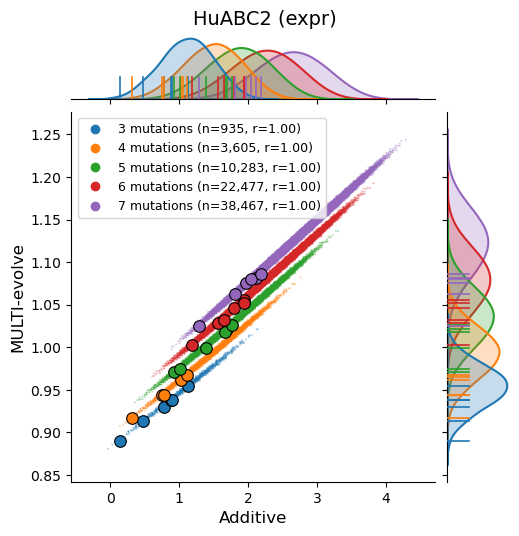

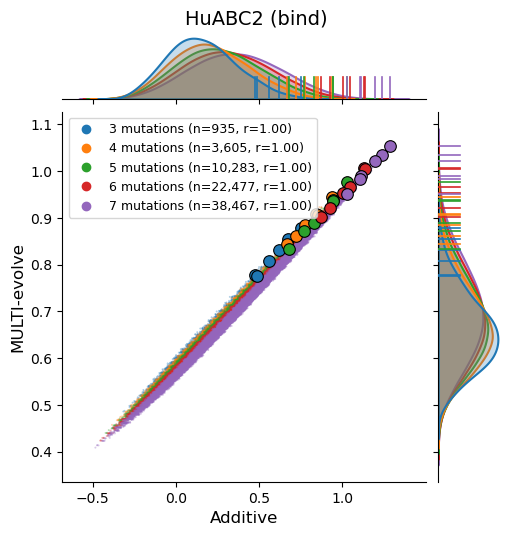

In [12]:
def make_jointplot(merged_df, tran_df, xcol, ycol, title, filename, ns=None):
    """Seaborn jointplot colored by mutation count."""
    if ns is None:
        ns = sorted(merged_df['n_muts'].unique())

    sub = merged_df[merged_df['n_muts'].isin(ns) & merged_df[ycol].notna()].copy()
    if len(sub) == 0:
        print(f'No data for {title} — skipping')
        return

    labels_in_order = []
    palette = {}
    label_map = {}
    colors = [f'C{i}' for i in range(len(ns))]
    for i, n in enumerate(ns):
        grp = sub[sub['n_muts'] == n]
        if len(grp) < 3:
            continue
        r, _ = pearsonr(grp[xcol], grp[ycol])
        label = f'{n} mutations (n={len(grp):,}, r={r:.2f})'
        labels_in_order.append(label)
        label_map[n] = label
        palette[label] = colors[i]
    sub['group'] = sub['n_muts'].map(label_map)
    sub = sub[sub['group'].notna()]
    sub['group'] = pd.Categorical(sub['group'], categories=labels_in_order, ordered=True)

    g = sns.jointplot(
        data=sub, x=xcol, y=ycol,
        hue='group', palette=palette,
        kind='scatter', height=5.2, ratio=5,
        marginal_kws={'common_norm': False, 'fill': True, 'linewidth': 1.5},
        joint_kws={'s': 2, 'alpha': 0.35, 'linewidth': 0, 'rasterized': True},
        hue_order=labels_in_order, legend=False,
    )

    # Overlay Tran et al. designs
    tran_sub = tran_df[tran_df['n_muts'].isin(ns) & tran_df[ycol].notna()].copy()
    for n in ns:
        if n not in label_map:
            continue
        color = palette[label_map[n]]
        tg = tran_sub[tran_sub['n_muts'] == n]
        if len(tg) == 0:
            continue
        g.ax_joint.scatter(tg[xcol], tg[ycol],
                          s=70, facecolor=color, edgecolors='black',
                          linewidths=0.8, zorder=5)
        for xv in tg[xcol]:
            g.ax_marg_x.axvline(xv, color=color, linewidth=1.2,
                                ymin=0.0, ymax=0.35, zorder=6)
        for yv in tg[ycol]:
            g.ax_marg_y.axhline(yv, color=color, linewidth=1.2,
                                xmin=0.0, xmax=0.35, zorder=6)

    g.ax_joint.set_xlabel('Additive', fontsize=12)
    g.ax_joint.set_ylabel('MULTI-evolve', fontsize=12)
    handles = [Line2D([0], [0], marker='o', linestyle='', color=palette[l],
                      markersize=6, label=l) for l in labels_in_order]
    g.ax_joint.legend(handles=handles, loc='upper left', fontsize=9, frameon=True)
    g.fig.suptitle(title, y=1.02, fontsize=14)
    g.fig.savefig(f'../figures/{filename}', bbox_inches='tight')
    plt.show()


ns = [3, 4, 5, 6, 7]

# Expression
if merged['multievolve_pred_expr'].notna().any():
    make_jointplot(merged, tran_merged,
                   'prediction_additive_logfc_expr', 'multievolve_pred_expr',
                   'HuABC2 (expr)', 'huabc2_expr_additive_vs_multievolve_jointplot.pdf',
                   ns=ns)
else:
    print('No MULTI-evolve expression predictions — skipping jointplot')

# Binding
if merged['multievolve_pred_bind'].notna().any():
    make_jointplot(merged, tran_merged,
                   'prediction_additive_logfc_bind', 'multievolve_pred_bind',
                   'HuABC2 (bind)', 'huabc2_bind_additive_vs_multievolve_jointplot.pdf',
                   ns=ns)
else:
    print('No MULTI-evolve binding predictions — skipping jointplot')

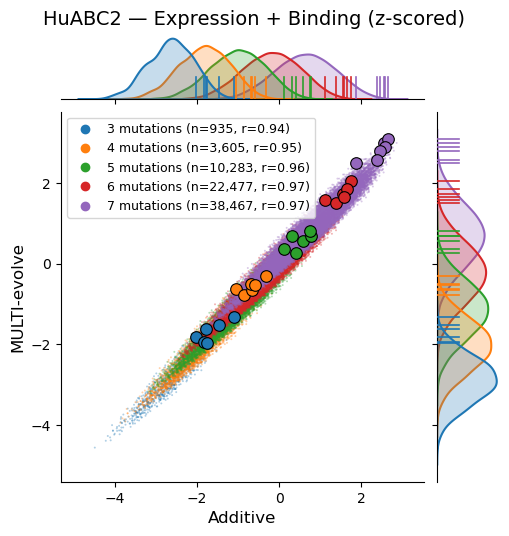

In [13]:
# Aggregate score: expression + binding (additive vs MULTI-evolve)
# Z-score each measurement before summing so that additive (log2 FC scale)
# and MULTI-evolve (y_scaled) contribute comparably.
for prefix, ecol, bcol in [
    ('prediction_additive',
     'prediction_additive_logfc_expr', 'prediction_additive_logfc_bind'),
    ('multievolve_pred',
     'multievolve_pred_expr', 'multievolve_pred_bind'),
]:
    valid = merged[ecol].notna() & merged[bcol].notna()
    e_z = (merged.loc[valid, ecol] - merged.loc[valid, ecol].mean()) / merged.loc[valid, ecol].std()
    b_z = (merged.loc[valid, bcol] - merged.loc[valid, bcol].mean()) / merged.loc[valid, bcol].std()
    merged[f'{prefix}_expr_plus_bind'] = np.nan
    merged.loc[valid, f'{prefix}_expr_plus_bind'] = (e_z + b_z).values

# Rebuild tran_merged with new columns
tran_merged = merged[merged['muts_s'].isin(targets)]

make_jointplot(merged, tran_merged,
               'prediction_additive_expr_plus_bind',
               'multievolve_pred_expr_plus_bind',
               'HuABC2 — Expression + Binding (z-scored)',
               'huabc2_expr_plus_bind_additive_vs_multievolve_jointplot.pdf',
               ns=[3, 4, 5, 6, 7])

## Tidy panel figure

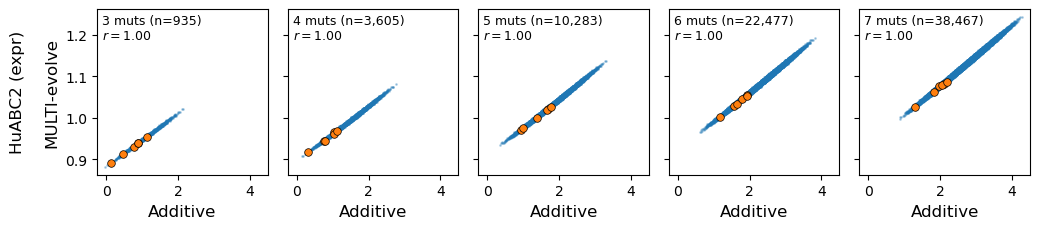

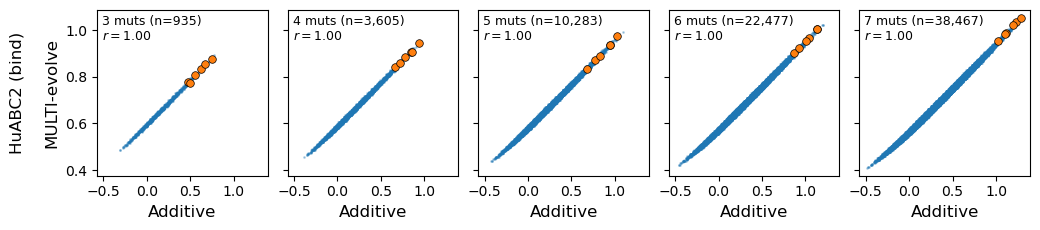

In [14]:
def plot_tidy_panels(merged_df, tran_df, col_add, col_me, title, filename, ns=None):
    """Row of scatter panels, one per mutation count."""
    if ns is None:
        ns = sorted(merged_df['n_muts'].unique())
    
    sub_all = merged_df[merged_df[col_me].notna()].copy()
    if len(sub_all) == 0:
        print(f'No data for {title} — skipping')
        return

    fig, axes = plt.subplots(1, len(ns), figsize=(2.1 * len(ns), 2.4),
                             sharex=True, sharey=True)
    if len(ns) == 1:
        axes = [axes]

    for j, n in enumerate(ns):
        ax = axes[j]
        sub = sub_all[sub_all['n_muts'] == n]
        tran_sub = tran_df[tran_df['n_muts'] == n]
        if col_me in tran_sub.columns:
            tran_sub = tran_sub[tran_sub[col_me].notna()]

        ax.scatter(sub[col_add], sub[col_me],
                   s=1, alpha=0.3, color='C0', rasterized=True)
        if len(tran_sub) > 0:
            ax.scatter(tran_sub[col_add], tran_sub[col_me],
                       s=30, color='C1', edgecolors='black',
                       linewidths=0.5, zorder=5)

        if len(sub) >= 3:
            r, _ = pearsonr(sub[col_add], sub[col_me])
            ax.text(0.03, 0.97, f'{n} muts (n={len(sub):,})\n$r = {r:.2f}$',
                    transform=ax.transAxes, ha='left', va='top', fontsize=9)
        ax.set_xlabel('Additive', fontsize=12)

    axes[0].set_ylabel(f'{title}\n\nMULTI-evolve', fontsize=12)
    plt.tight_layout()
    fig.savefig(f'../figures/{filename}', bbox_inches='tight')
    plt.show()


ns = [3, 4, 5, 6, 7]

if merged['multievolve_pred_expr'].notna().any():
    plot_tidy_panels(merged, tran_merged,
                     'prediction_additive_logfc_expr', 'multievolve_pred_expr',
                     'HuABC2 (expr)', 'huabc2_expr_additive_vs_multievolve_tidy.pdf', ns=ns)
else:
    print('No MULTI-evolve expression predictions — skipping tidy panels')

if merged['multievolve_pred_bind'].notna().any():
    plot_tidy_panels(merged, tran_merged,
                     'prediction_additive_logfc_bind', 'multievolve_pred_bind',
                     'HuABC2 (bind)', 'huabc2_bind_additive_vs_multievolve_tidy.pdf', ns=ns)
else:
    print('No MULTI-evolve binding predictions — skipping tidy panels')

## Additive ridge vs naive sum and 0-layer NN

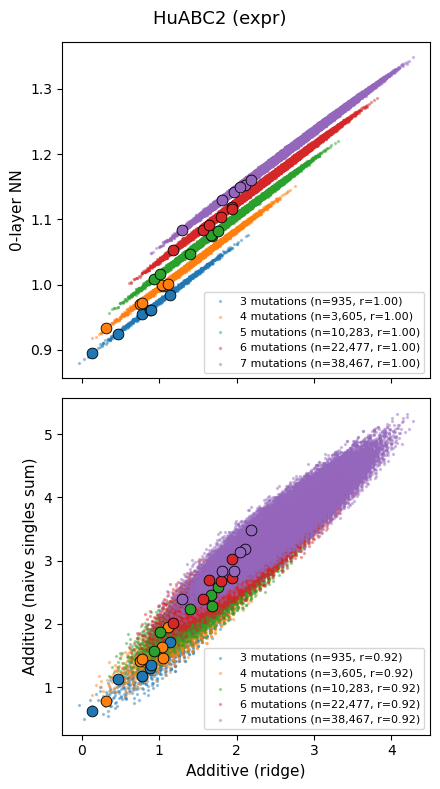

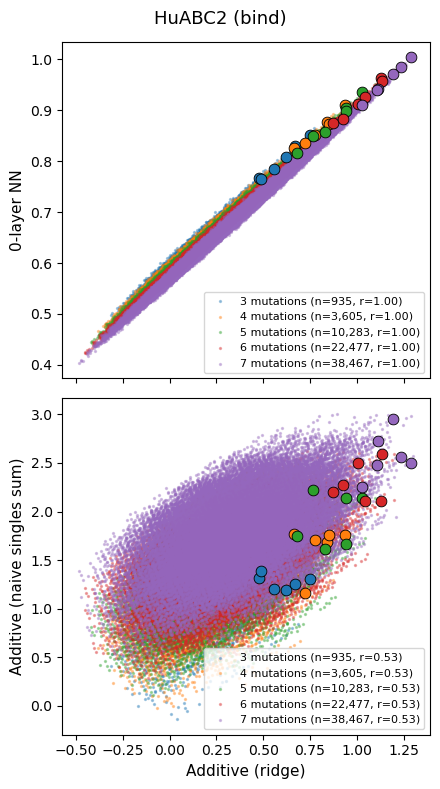

In [15]:
ns = [3, 4, 5, 6, 7]
colors = [f'C{i}' for i in range(len(ns))]

for measurement, tag, short in [('expr', 'logfc_expr', 'expr'),
                                ('bind', 'logfc_bind', 'bind')]:
    col_ridge = f'prediction_additive_{tag}'
    col_0lay  = f'prediction_0layer_{short}'
    col_naive = f'prediction_naive_{tag}'

    has_0layer = col_0lay in merged.columns and merged[col_0lay].notna().any()
    n_panels = 2 if has_0layer else 1

    fig, axes = plt.subplots(n_panels, 1, figsize=(4.5, 4 * n_panels), sharex=True)
    if n_panels == 1:
        axes = [axes]

    panel_defs = []
    if has_0layer:
        panel_defs.append((axes[0], col_ridge, col_0lay, '', '0-layer NN'))
        panel_defs.append((axes[1], col_ridge, col_naive, 'Additive (ridge)',
                           'Additive (naive singles sum)'))
    else:
        panel_defs.append((axes[0], col_ridge, col_naive, 'Additive (ridge)',
                           'Additive (naive singles sum)'))

    for ax, xcol, ycol, xlab, ylab in panel_defs:
        sub = merged[merged[ycol].notna()].copy()
        sub['n_muts'] = sub['muts'].apply(len)
        tsub = tran_merged[tran_merged[ycol].notna()].copy()
        tsub['n_muts'] = tsub['muts'].apply(len)

        for i, n in enumerate(ns):
            grp  = sub[sub['n_muts'] == n]
            tgrp = tsub[tsub['n_muts'] == n]
            if len(grp) < 3:
                continue
            r, _ = pearsonr(grp[xcol], grp[ycol])
            ax.scatter(grp[xcol], grp[ycol], s=2, alpha=0.35, color=colors[i],
                       rasterized=True,
                       label=f'{n} mutations (n={len(grp):,}, r={r:.2f})')
            if len(tgrp):
                ax.scatter(tgrp[xcol], tgrp[ycol], s=60, color=colors[i],
                           edgecolors='black', linewidths=0.6, zorder=5)
        ax.set_xlabel(xlab, fontsize=11)
        ax.set_ylabel(ylab, fontsize=11)
        ax.legend(fontsize=8, loc='lower right', frameon=True)

    fig.suptitle(f'HuABC2 ({measurement})', fontsize=13)
    plt.tight_layout()
    safe = short
    fig.savefig(f'../figures/huabc2_{safe}_ridge_vs_0layer_and_naive.pdf',
                bbox_inches='tight')
    plt.show()

## Expression–binding Pareto frontier (supplementary, 3–7 mutations)

Tran et al. selected HuABC2 multimutants along the expression–binding
Pareto frontier. Here we visualise this two-objective landscape under
the additive ridge and FCNN models, with separate panels for each
mutation count (3–7), and overlay the measured outcomes for the 30
MULTI-evolve variants.

In [16]:
def pareto_frontier(xs, ys, maximize_x=True, maximize_y=True):
    """Return indices of Pareto-optimal points (maximise both objectives)."""
    pts = np.column_stack([xs, ys])
    if not maximize_x:
        pts[:, 0] = -pts[:, 0]
    if not maximize_y:
        pts[:, 1] = -pts[:, 1]
    # Sort by first objective descending, then second descending
    order = np.lexsort((-pts[:, 1], -pts[:, 0]))
    pareto_idx = [order[0]]
    best_y = pts[order[0], 1]
    for idx in order[1:]:
        if pts[idx, 1] > best_y:
            pareto_idx.append(idx)
            best_y = pts[idx, 1]
    return np.array(pareto_idx)


def _point_to_segment_dist(px, py, ax, ay, bx, by):
    """Minimum distance from point (px, py) to line segment (a→b)."""
    dx, dy = bx - ax, by - ay
    len_sq = dx * dx + dy * dy
    if len_sq == 0:
        return np.hypot(px - ax, py - ay)
    t = np.clip(((px - ax) * dx + (py - ay) * dy) / len_sq, 0, 1)
    proj_x = ax + t * dx
    proj_y = ay + t * dy
    return np.hypot(px - proj_x, py - proj_y)


def dist_to_pareto(xs, ys, frontier_xs, frontier_ys, x_range, y_range):
    """Signed-ish min distance from each point to the Pareto frontier curve.

    Coordinates are normalised by (x_range, y_range) so that distance is
    scale-free.  Points dominated by the frontier get positive distance;
    points on/above the frontier get ~0.

    Parameters
    ----------
    xs, ys : 1-D arrays  – query points (raw scale)
    frontier_xs, frontier_ys : 1-D arrays – frontier vertices sorted by x
    x_range, y_range : float – ranges used to normalise axes to [0, 1]
    """
    # Normalise
    fxn = frontier_xs / x_range
    fyn = frontier_ys / y_range
    pxn = xs / x_range
    pyn = ys / y_range

    n_seg = len(fxn) - 1
    dists = np.full(len(pxn), np.inf)
    for i in range(max(n_seg, 1)):
        ax, ay = fxn[i], fyn[i]
        bx, by = (fxn[i + 1], fyn[i + 1]) if n_seg > 0 else (ax, ay)
        for k in range(len(pxn)):
            d = _point_to_segment_dist(pxn[k], pyn[k], ax, ay, bx, by)
            if d < dists[k]:
                dists[k] = d
    return dists

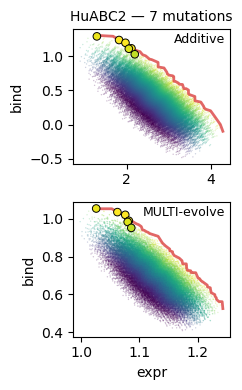

In [17]:
# ── Main-text figure: two-panel 7-mutation Pareto (Additive | MULTI-evolve) ──
# Points colored by distance from the *additive* Pareto frontier.
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

N_MAIN = 7
CMAP = 'viridis_r'

# ── Compute additive Pareto frontier & distances for N_MAIN mutations ──
add_ecol = 'prediction_additive_logfc_expr'
add_bcol = 'prediction_additive_logfc_bind'

sub_add = merged[merged['n_muts'] == N_MAIN].dropna(subset=[add_ecol, add_bcol]).copy()
pidx_add = pareto_frontier(sub_add[add_ecol].values, sub_add[add_bcol].values)
pf_add = sub_add.iloc[pidx_add].sort_values(add_ecol)

# Normalisation ranges (shared across panels for consistent colouring)
x_range = sub_add[add_ecol].max() - sub_add[add_ecol].min()
y_range = sub_add[add_bcol].max() - sub_add[add_bcol].min()

# Distance of every variant from additive frontier (keyed by muts_s)
all_dists = dist_to_pareto(
    sub_add[add_ecol].values, sub_add[add_bcol].values,
    pf_add[add_ecol].values, pf_add[add_bcol].values,
    x_range, y_range,
)
dist_map = dict(zip(sub_add['muts_s'].values, all_dists))

# Colour normalisation
vmax = np.percentile(all_dists, 95)
norm = Normalize(vmin=0, vmax=vmax)
cmap = plt.get_cmap(CMAP)

# ── Panel specs ──
panel_specs = [('Additive', add_ecol, add_bcol)]

has_fcnn = (merged['multievolve_pred_expr'].notna().any() and
            merged['multievolve_pred_bind'].notna().any())
if has_fcnn:
    panel_specs.append(('MULTI-evolve',
                        'multievolve_pred_expr',
                        'multievolve_pred_bind'))

n_panels = len(panel_specs)
fig, axes = plt.subplots(n_panels, 1, figsize=(2.5, 2 * n_panels), squeeze=False)

for j, (label, ecol, bcol) in enumerate(panel_specs):
    ax = axes[j, 0]
    sub = merged[merged['n_muts'] == N_MAIN].dropna(subset=[ecol, bcol]).copy()
    tsub = tran_merged[tran_merged['n_muts'] == N_MAIN].dropna(subset=[ecol, bcol]).copy()

    # Look up distance from additive frontier for each variant
    sub_d = sub['muts_s'].map(dist_map).values
    tsub_d = tsub['muts_s'].map(dist_map).values

    # Background cloud coloured by distance
    ax.scatter(sub[ecol], sub[bcol],
               c=sub_d, cmap=CMAP, norm=norm,
               s=1, alpha=0.25, linewidth=0, rasterized=True)

    # Pareto frontier (of this panel's model)
    pidx = pareto_frontier(sub[ecol].values, sub[bcol].values)
    pf = sub.iloc[pidx].sort_values(ecol)
    ax.plot(pf[ecol], pf[bcol],
            color='C3', linewidth=2, linestyle='-', alpha=0.7)

    # Tran et al. designs coloured by distance
    if len(tsub) > 0:
        ax.scatter(tsub[ecol], tsub[bcol],
                   c=tsub_d, cmap=CMAP, norm=norm,
                   s=30, edgecolors='black',
                   linewidths=0.7, zorder=6)

    ax.annotate(label, xy=(0.97, 0.97), xycoords='axes fraction',
                ha='right', va='top', fontsize=9)
    ax.set_ylabel('bind', fontsize=10)
    if j == n_panels - 1:
        ax.set_xlabel('expr', fontsize=10)
    if j == 0:
        ax.set_title(f'HuABC2 — 7 mutations', fontsize=10)

# Colorbar
# sm = ScalarMappable(cmap=CMAP, norm=norm)
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.6, pad=0.08)
# cbar.set_label('Distance from\nadditive Pareto', fontsize=8)

plt.tight_layout()
fig.savefig('../figures/huabc2_pareto_7mut_main.pdf', bbox_inches='tight')
plt.show()

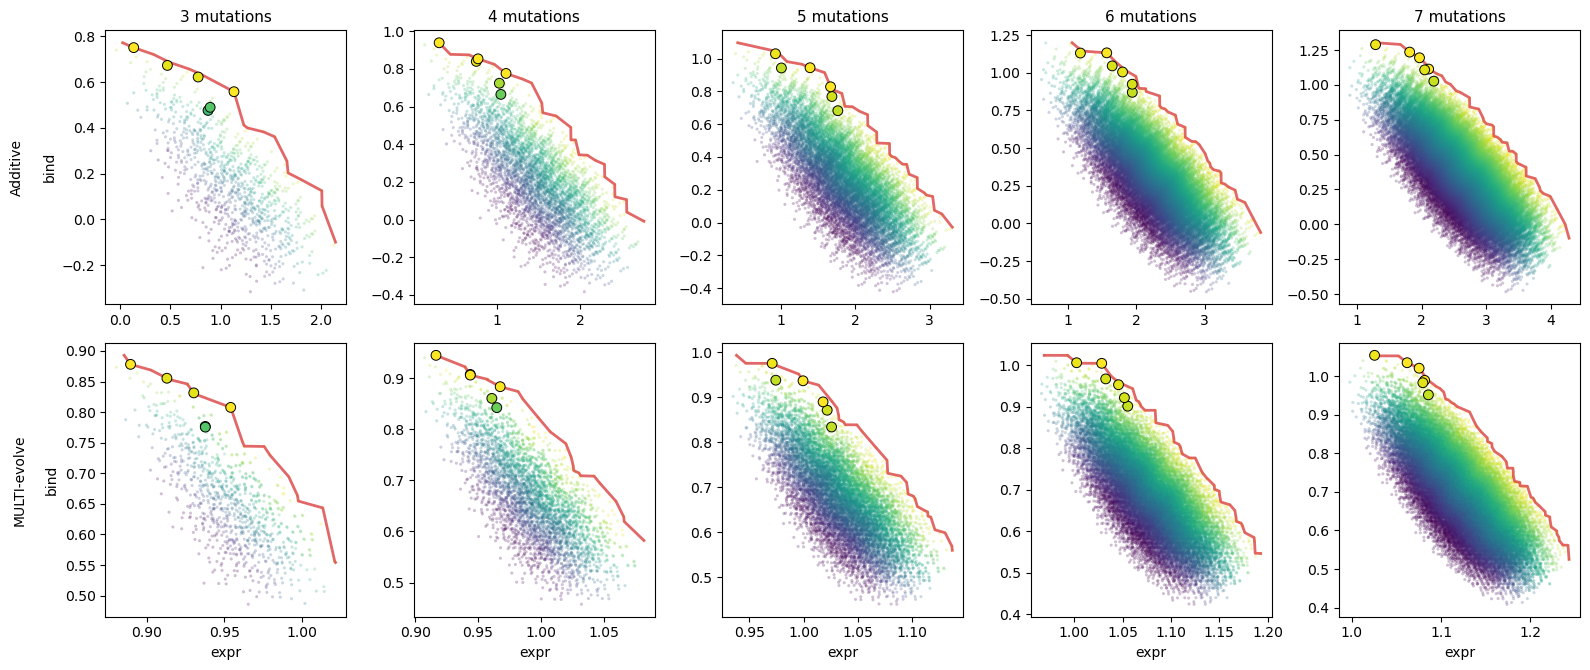

Models: ['Additive', 'MULTI-evolve'], mutation counts: [3, 4, 5, 6, 7]


In [18]:
# ── Supplementary: Pareto frontier, rows = models, columns = mutation count ──
# Points colored by distance from the *additive* Pareto frontier.
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

CMAP = 'viridis_r'
add_ecol = 'prediction_additive_logfc_expr'
add_bcol = 'prediction_additive_logfc_bind'

model_specs = []  # (label, expr_col, bind_col)
model_specs.append(('Additive', add_ecol, add_bcol))

has_fcnn = (merged['multievolve_pred_expr'].notna().any() and
            merged['multievolve_pred_bind'].notna().any())
if has_fcnn:
    model_specs.append(('MULTI-evolve',
                        'multievolve_pred_expr',
                        'multievolve_pred_bind'))

ns = [3, 4, 5, 6, 7]
n_rows = len(model_specs)
n_cols = len(ns)

# ── Pre-compute additive Pareto distances per mutation count ──
dist_maps = {}   # n -> {muts_s: distance}
vmax_all = 0
for n in ns:
    sub_n = merged[merged['n_muts'] == n].dropna(subset=[add_ecol, add_bcol]).copy()
    if len(sub_n) < 2:
        dist_maps[n] = {}
        continue
    pidx = pareto_frontier(sub_n[add_ecol].values, sub_n[add_bcol].values)
    pf = sub_n.iloc[pidx].sort_values(add_ecol)
    x_range = sub_n[add_ecol].max() - sub_n[add_ecol].min()
    y_range = sub_n[add_bcol].max() - sub_n[add_bcol].min()
    if x_range == 0:
        x_range = 1
    if y_range == 0:
        y_range = 1
    dists = dist_to_pareto(
        sub_n[add_ecol].values, sub_n[add_bcol].values,
        pf[add_ecol].values, pf[add_bcol].values,
        x_range, y_range,
    )
    dist_maps[n] = dict(zip(sub_n['muts_s'].values, dists))
    vmax_all = max(vmax_all, np.percentile(dists, 95))

norm = Normalize(vmin=0, vmax=vmax_all)

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(3.2 * n_cols, 3.4 * n_rows),
                         squeeze=False)

for row, (model_label, ecol, bcol) in enumerate(model_specs):
    sub_all = merged.dropna(subset=[ecol, bcol]).copy()
    tsub_all = tran_merged.dropna(subset=[ecol, bcol]).copy()

    for col, n in enumerate(ns):
        ax = axes[row, col]
        sub = sub_all[sub_all['n_muts'] == n]
        tsub = tsub_all[tsub_all['n_muts'] == n]

        if len(sub) == 0:
            ax.text(0.5, 0.5, 'no data', transform=ax.transAxes,
                    ha='center', va='center')
            continue

        # Look up additive-frontier distance for each variant
        dm = dist_maps[n]
        sub_d = sub['muts_s'].map(dm).values
        tsub_d = tsub['muts_s'].map(dm).values if len(tsub) > 0 else np.array([])

        # Background cloud coloured by distance from additive frontier
        ax.scatter(sub[ecol], sub[bcol],
                   c=sub_d, cmap=CMAP, norm=norm,
                   s=5, alpha=0.25, linewidth=0, rasterized=True)

        # Pareto frontier for this panel's model
        xs = sub[ecol].values
        ys = sub[bcol].values
        pidx = pareto_frontier(xs, ys)
        pf = sub.iloc[pidx].sort_values(ecol)
        ax.plot(pf[ecol], pf[bcol],
                color='C3', linewidth=2, linestyle='-', alpha=0.7)

        # Tran et al. designs
        if len(tsub) > 0:
            ax.scatter(tsub[ecol], tsub[bcol],
                       c=tsub_d, cmap=CMAP, norm=norm,
                       s=50, edgecolors='black',
                       linewidths=0.7, zorder=6)

        if row == 0:
            ax.set_title(f'{n} mutations', fontsize=11)
        if row == n_rows - 1:
            ax.set_xlabel('expr', fontsize=10)
        if col == 0:
            ax.set_ylabel(f'{model_label}\n\nbind', fontsize=10)

# # Shared colorbar
# sm = ScalarMappable(cmap=CMAP, norm=norm)
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.5, pad=0.03)
# cbar.set_label('Distance from additive Pareto', fontsize=9)

plt.tight_layout()
fig.savefig('../figures/huabc2_pareto_expr_vs_bind_supp.pdf', bbox_inches='tight')
plt.show()

print(f'Models: {[s[0] for s in model_specs]}, mutation counts: {ns}')